# Figure source — Self-supervised training curves

This notebook plots the training histories of the EMA-distillation and MAE-style SSL conditions. The two losses correspond to different objectives and should not be compared numerically.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

['epoch', 'loss', 'lr']


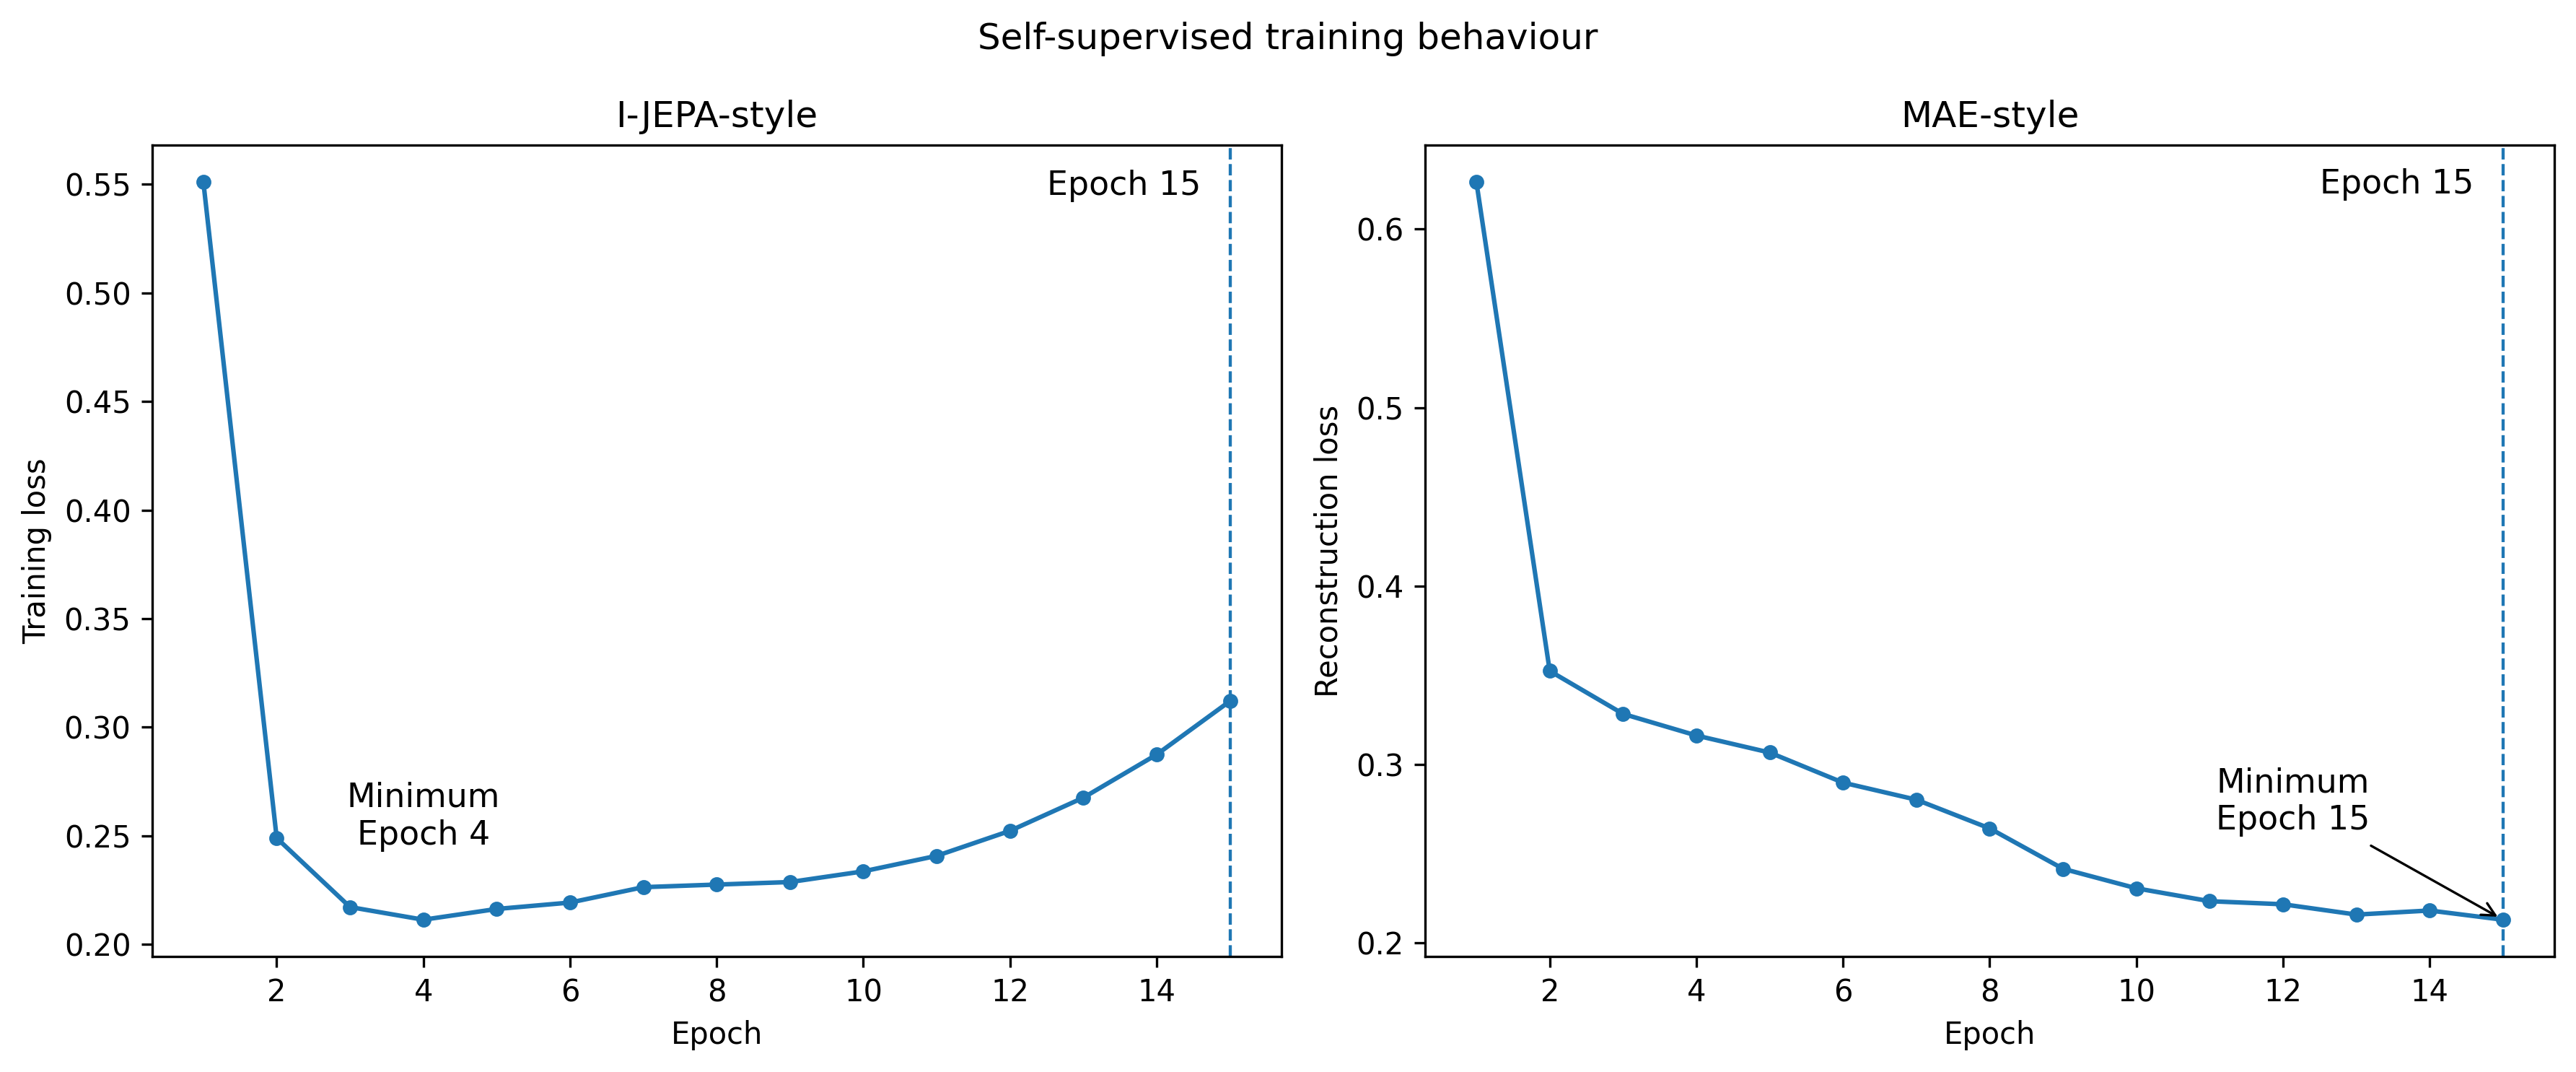

In [ ]:
def loss_col(df):
    candidates = [c for c in df.columns if 'loss' in c.lower()]
    if not candidates:
        raise ValueError(f"No loss column found. Columns are: {df.columns.tolist()}")
    return candidates[0]

ij = pd.read_csv('/content/ssl_corrected_2840_history.csv')
ma = pd.read_csv('/content/mae_corrected_2840_history.csv')

print(ma.columns.tolist())

fig, axes = plt.subplots(1, 2, figsize=(12, 5), dpi=300)

axes[0].plot(ij['epoch'], ij[loss_col(ij)], '-o', ms=4)
axes[0].set_title('I-JEPA-style'); axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Training loss')
imin = ij[loss_col(ij)].idxmin()
axes[0].annotate('Minimum\nEpoch 4',
                 xy=(ij['epoch'][imin], ij[loss_col(ij)][imin]),
                 xytext=(0, 25), textcoords='offset points', ha='center', fontsize=11)
axes[0].axvline(15, ls='--', lw=1)

axes[1].plot(ma['epoch'], ma[loss_col(ma)], '-o', ms=4)
axes[1].set_title('MAE-style'); axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Reconstruction loss')
axes[1].axvline(15, ls='--', lw=1)

for a in axes:
    a.axvline(15, ls='--', lw=1)
    a.text(14.6, a.get_ylim()[1]*0.98, 'Epoch 15', ha='right', va='top', fontsize=11)

imin_ma = ma[loss_col(ma)].idxmin()
axes[1].annotate('Minimum\nEpoch 15',
                 xy=(ma['epoch'][imin_ma], ma[loss_col(ma)][imin_ma]),
                 xytext=(-70, 30), textcoords='offset points',
                 ha='center', fontsize=11,
                 arrowprops=dict(arrowstyle='->', lw=0.8))

fig.suptitle('Self-supervised training behaviour')
fig.tight_layout()
fig.savefig('Fig8_training_300dpi.png', dpi=300, bbox_inches='tight')